###  **Title: DSC680-T301 Applied Data Science (2271-1)**
####  **Professor:** *Xu Ashton*
####  **Date: 26 Sep 2026**
####  **Author:** *Akhil Anand Thazhaniyil Muralidharan*
####  **Description:** Week10 Milestone 2: Smart Payment Retry: Reproducible Analysis

*************

* This notebook reproduces data preparation, exploratory analysis, classification, validation, explainability, and retry-policy comparison. 
* The input CSV contains **84,516 synthetic invoices**. No real payment or personally identifiable information is used.

*********


### Research Questions
1. Which account and payment characteristics are associated with initial payment failures?
2. Can retry success be predicted with useful precision and recall?
3. Which model offers the best F1/ROC-AUC balance?
4. Can a smart policy reduce unnecessary attempts while preserving automatic recovery?

Because outcomes are simulated, results demonstrate the method rather than causal production performance.

**********

### Setup and Reproducibility

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.inspection import permutation_importance
SEED=680
DATA=Path('smart_payment_retry_84516_invoices.csv')
if not DATA.exists(): DATA=Path('/mnt/data/smart_payment_retry_84516_invoices.csv')


### Load and Audit Data
Inspect shape, unique invoice IDs, missing values, and duplicates. Missing payment methods are labeled `Unknown`; no invoices are dropped.


In [2]:
df=pd.read_csv(DATA)
print('Shape:',df.shape)
print('Unique invoices:',df.invoice_id.nunique())
print('Duplicate invoice IDs:',df.invoice_id.duplicated().sum())
print(df.isna().sum()[df.isna().sum()>0])
df['primary_payment_method']=df['primary_payment_method'].fillna('Unknown')
df['billing_month']=pd.to_datetime(df['billing_month'])
df['due_date']=pd.to_datetime(df['due_date'])
df.head()


Shape: (84516, 22)
Unique invoices: 84516
Duplicate invoice IDs: 0
primary_payment_method      338
failure_category          75076
dtype: int64


,invoice_id,customer_id,billing_month,due_date,invoice_amount,tenure_months,contract_type,primary_payment_method,senior_citizen,autopay_enrolled,...,initial_payment_failed,failure_category,decline_code,soft_or_hard_decline,retry_needed,recommended_retry_delay_hours,total_attempts,retry_success,final_outcome,customer_contact_required
0,INV-202501-00001,C00001,2025-01-01,2025-01-05,114.19,72,Month-to-month,Bank transfer (automatic),0,1,...,1,Insufficient funds,51,soft,1,72,2,0,Manual action/contact required,1
1,INV-202501-00002,C00002,2025-01-01,2025-01-10,118.43,37,Two year,Bank transfer (automatic),0,1,...,0,NaN,APPROVED,none,0,0,1,0,Paid - initial,0
2,INV-202501-00003,C00003,2025-01-01,2025-01-15,37.55,14,Month-to-month,Bank transfer (automatic),0,1,...,0,NaN,APPROVED,none,0,0,1,0,Paid - initial,0
3,INV-202501-00004,C00004,2025-01-01,2025-01-10,94.35,22,Month-to-month,Credit card (automatic),0,1,...,0,NaN,APPROVED,none,0,0,1,0,Paid - initial,0
4,INV-202501-00005,C00005,2025-01-01,2025-01-25,37.96,20,One year,Electronic check,0,0,...,1,Bank/issuer decline,05,soft,1,48,2,1,Recovered automatically,0


### Data Dictionary
Key groups are customer/account context, invoice characteristics, failure details, retry actions, and outcomes. `retry_success` is the binary target for initially failed invoices.


In [3]:
dictionary=pd.DataFrame([
['invoice_id','Unique synthetic invoice identifier'],['customer_id','Synthetic customer identifier used for grouped splitting'],['billing_month','Invoice month'],['invoice_amount','Synthetic monthly amount in USD'],['primary_payment_method','Primary collection method'],['autopay_enrolled','1 if autopay is enabled'],['failure_category','Simulated root cause'],['decline_code','Synthetic gateway-style decline code'],['soft_or_hard_decline','Recoverability classification'],['recommended_retry_delay_hours','Candidate delay'],['retry_success','1 if automated retry recovered payment'],['customer_contact_required','1 if automation did not resolve payment']],columns=['Field','Definition'])
dictionary


,Field,Definition
0,invoice_id,Unique synthetic invoice identifier
1,customer_id,Synthetic customer identifier used for grouped...
2,billing_month,Invoice month
3,invoice_amount,Synthetic monthly amount in USD
4,primary_payment_method,Primary collection method
5,autopay_enrolled,1 if autopay is enabled
6,failure_category,Simulated root cause
7,decline_code,Synthetic gateway-style decline code
8,soft_or_hard_decline,Recoverability classification
9,recommended_retry_delay_hours,Candidate delay


### Exploratory Comparison
These views compare initial successes and failures and examine the operational root-cause mix.


Initial failure rate: 0.1117
Retry recovery rate: 0.4849


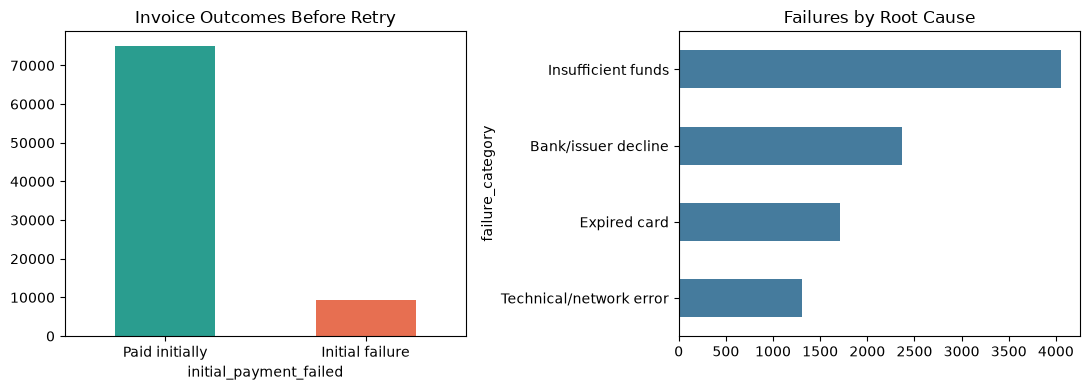

In [4]:
failed=df[df.initial_payment_failed==1].copy()
print('Initial failure rate:',round(df.initial_payment_failed.mean(),4))
print('Retry recovery rate:',round(failed.retry_success.mean(),4))
fig,axs=plt.subplots(1,2,figsize=(11,4))
df.initial_payment_failed.value_counts().sort_index().plot.bar(ax=axs[0],color=['#2a9d8f','#e76f51'])
axs[0].set_xticklabels(['Paid initially','Initial failure'],rotation=0); axs[0].set_title('Invoice Outcomes Before Retry')
failed.failure_category.value_counts().plot.barh(ax=axs[1],color='#457b9d'); axs[1].set_title('Failures by Root Cause'); axs[1].invert_yaxis()
plt.tight_layout(); plt.show()


### Modeling Method and Justification
Logistic Regression is the interpretable baseline, Decision Tree offers auditable rules, Random Forest captures nonlinear interactions, and HistGradientBoosting is a strong tabular learner. Customer-grouped splitting prevents customer leakage. Preprocessing is fitted inside the pipeline.


In [5]:
features=['invoice_amount','tenure_months','contract_type','primary_payment_method','senior_citizen','autopay_enrolled','alternate_payment_available','service_bundle','failure_category','decline_code','soft_or_hard_decline','recommended_retry_delay_hours']
X=failed[features]; y=failed.retry_success; groups=failed.customer_id
num=['invoice_amount','tenure_months','senior_citizen','autopay_enrolled','alternate_payment_available','recommended_retry_delay_hours']; cat=[c for c in features if c not in num]
pre=ColumnTransformer([('num',Pipeline([('imp',SimpleImputer(strategy='median')),('sc',StandardScaler())]),num),('cat',Pipeline([('imp',SimpleImputer(strategy='most_frequent')),('oh',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),cat)])
tr,te=next(GroupShuffleSplit(n_splits=1,test_size=.25,random_state=SEED).split(X,y,groups))
Xtr,Xte=X.iloc[tr],X.iloc[te]; ytr,yte=y.iloc[tr],y.iloc[te]
models={'Logistic Regression':LogisticRegression(max_iter=1000,class_weight='balanced',random_state=SEED),'Decision Tree':DecisionTreeClassifier(max_depth=7,min_samples_leaf=40,class_weight='balanced',random_state=SEED),'Random Forest':RandomForestClassifier(n_estimators=180,max_depth=12,min_samples_leaf=8,class_weight='balanced',n_jobs=-1,random_state=SEED),'HistGradientBoosting':HistGradientBoostingClassifier(max_iter=160,max_leaf_nodes=20,learning_rate=.07,l2_regularization=.3,random_state=SEED)}


### Evaluation
Precision, recall, F1, and ROC-AUC are reported. Accuracy is not emphasized because most invoices are initially successful.


In [6]:
rows=[]; fitted={}
for name,m in models.items():
    p=Pipeline([('prep',pre),('model',m)]).fit(Xtr,ytr); fitted[name]=p
    prob=p.predict_proba(Xte)[:,1]; pred=(prob>=.5).astype(int)
    rows.append([name,precision_score(yte,pred),recall_score(yte,pred),f1_score(yte,pred),roc_auc_score(yte,prob)])
results=pd.DataFrame(rows,columns=['Model','Precision','Recall','F1','ROC_AUC']).sort_values('F1',ascending=False)
results.round(3)


,Model,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.637,0.744,0.686,0.747
1,Decision Tree,0.632,0.739,0.682,0.738
2,Random Forest,0.628,0.744,0.681,0.740
3,HistGradientBoosting,0.642,0.715,0.676,0.740


Best model: Logistic Regression
[[730 480]
 [291 844]]


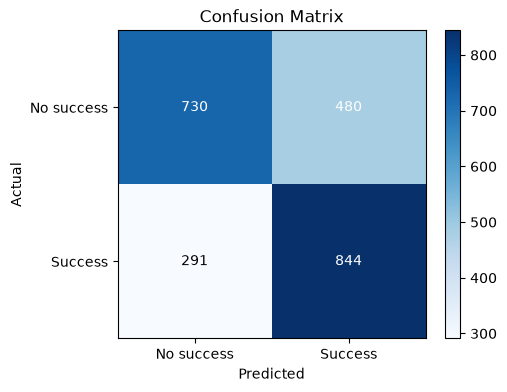

In [7]:
best_name=results.iloc[0].Model; best=fitted[best_name]
prob=best.predict_proba(Xte)[:,1]; pred=(prob>=.5).astype(int)
cm=confusion_matrix(yte,pred)
print('Best model:',best_name); print(cm)
fig,ax=plt.subplots(figsize=(5,4)); im=ax.imshow(cm,cmap='Blues')
ax.set_xticks([0,1],['No success','Success']); ax.set_yticks([0,1],['No success','Success']); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
for i in range(2):
    for j in range(2): ax.text(j,i,cm[i,j],ha='center',va='center',color='white' if cm[i,j]>cm.max()/2 else 'black')
plt.title('Confusion Matrix'); plt.colorbar(im); plt.show()


### Explainability
Permutation importance measures decrease in held-out F1 when each feature is shuffled. These are associations in simulated data, not causal effects.


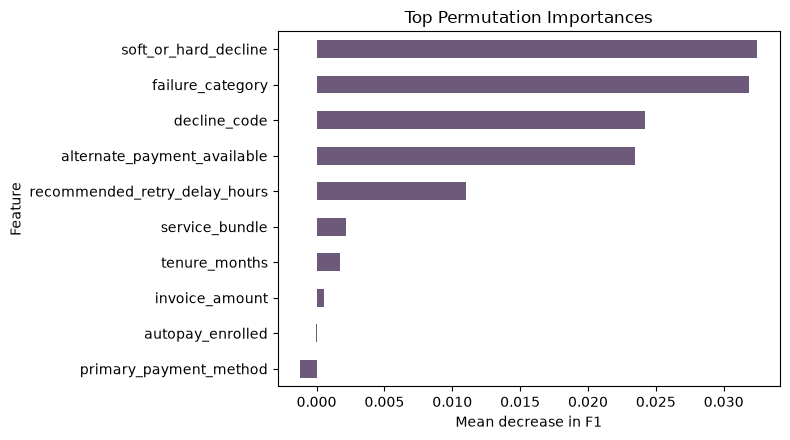

,Feature,Importance
10,soft_or_hard_decline,0.032464
8,failure_category,0.031892
9,decline_code,0.024206
6,alternate_payment_available,0.023479
11,recommended_retry_delay_hours,0.011011
7,service_bundle,0.002152
1,tenure_months,0.001703
0,invoice_amount,0.000572
5,autopay_enrolled,-0.000054
3,primary_payment_method,-0.001192


In [8]:
perm=permutation_importance(best,Xte,yte,n_repeats=5,random_state=SEED,scoring='f1',n_jobs=-1)
imp=pd.DataFrame({'Feature':features,'Importance':perm.importances_mean}).sort_values('Importance',ascending=False)
imp.head(10).sort_values('Importance').plot.barh(x='Feature',y='Importance',legend=False,color='#6d597a',figsize=(8,4.5),title='Top Permutation Importances')
plt.xlabel('Mean decrease in F1'); plt.tight_layout(); plt.show()
imp.head(10)


### Fixed Retry vs. Smart Retry Policy
The fixed policy retries all failures. The smart policy retries when probability is at least 0.55, the failure is technical, or an alternate payment method exists.


In [9]:
hold=failed.loc[Xte.index].copy(); hold['prob']=prob
smart=(hold.prob>=.55)|(hold.failure_category=='Technical/network error')|(hold.alternate_payment_available==1)
policy=pd.DataFrame({'Metric':['Recovered automatically','Retry attempts used','Wasted retries on hard declines','Customers requiring contact'],'Fixed retry':[int(hold.retry_success.sum()),int((hold.total_attempts-1).clip(lower=1).sum()),int(((hold.soft_or_hard_decline=='hard')&(hold.retry_success==0)).sum()),int((hold.retry_success==0).sum())],'Smart retry':[int(((hold.retry_success==1)&smart).sum()),int(smart.sum()),int(((hold.soft_or_hard_decline=='hard')&(hold.retry_success==0)&smart).sum()),int((~((hold.retry_success==1)&smart)).sum())]})
policy


,Metric,Fixed retry,Smart retry
0,Recovered automatically,1135,791
1,Retry attempts used,2648,1271
2,Wasted retries on hard declines,602,163
3,Customers requiring contact,1210,1554


### Ethical Assessment and Limitations
- **Privacy:** Tokenize IDs, enforce least privilege, encryption, and minimal retention.
- **Fairness:** Audit subgroup false-positive and false-negative rates.
- **Customer harm:** Cap attempts and suppress hard-decline retries.
- **Misuse:** Restrict scores to supportive recovery, not service denial, pricing, or punitive collections.
- **Validity:** Replace simulation performance with shadow-mode production evidence.


## Conclusion
The proof of concept shows that operational reason codes and account context can support retry-success prediction and policy comparison. The next step is a monitored shadow pilot with calibrated thresholds, retry caps, drift monitoring, and human review.
